# 13. f01_study_domain

Fig. 1. Study domain map, hydroclimatic setting and record coverage. Requires basemap-data. Station coordinates are approximate.

Run the notebooks in numerical order (each reads outputs of earlier steps from `results/`).

In [1]:
import os, sys
try:
    sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
except NameError:  # running inside a Jupyter notebook
    sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))
from config import *  # sets paths; working directory becomes results/

In [2]:
import numpy as np, matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon
import matplotlib.patheffects as pe
from PIL import Image; Image.MAX_IMAGE_PIXELS=None
from geo import read, P
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':7.5,'axes.linewidth':.6})
SR=np.asarray(Image.open(P+'shadedrelief.jpg'))
COL={'Lancang':'#1b9e77','Shule':'#d95f02','Tarim':'#7570b3','Nu':'#e7298a','Yarlung Tsangpo':'#66a61e','Indus':'#e6ab02','Jinsha':'#1f4e9c'}
st=lambda : [pe.withStroke(linewidth=2.2,foreground='white')]
ext=[68,123,22,45]
fig=plt.figure(figsize=(7.4,7.4)); ax=fig.add_axes([0.06,0.43,0.92,0.55])
W,H=SR.shape[1],SR.shape[0]; x0=int((ext[0]+180)/360*W); x1=int((ext[1]+180)/360*W); y0=int((90-ext[3])/180*H); y1=int((90-ext[2])/180*H)
ax.imshow(SR[y0:y1,x0:x1],extent=ext,origin='upper',interpolation='bilinear',zorder=0)
bb=(ext[0]-2,ext[1]+2,ext[2]-2,ext[3]+2)
for lev,a in read('gshhs','i',bb):
  if lev==1: ax.plot(a[:,0],a[:,1],color='#4d6b88',lw=.5,zorder=2)
  if lev==2: ax.add_patch(Polygon(a,closed=True,fc='#a9cbe6',ec='#3d6f9e',lw=.3,zorder=3))
for lev,a in read('countries','i',bb): ax.plot(a[:,0],a[:,1],color='0.3',lw=.45,ls=(0,(4,2)),zorder=2)
for lev,a in read('rivers','i',bb): ax.plot(a[:,0],a[:,1],color='#2f6fae',lw=.45,alpha=.8,zorder=3)
# stations (approximate coordinates; to be verified)
S=[('Xiangda','Lancang',96.48,32.25),('Jiuzhou','Lancang',99.25,25.95),('Changmabao','Shule',96.85,39.82),('Panjiazhuang','Shule',97.0,40.25),
   ('Kaqun','Tarim',76.90,37.98),('Tongguziluoke','Tarim',79.90,36.80),('Xindahe','Tarim',80.30,41.40),('Yanqi','Tarim',86.57,42.05),('Alar','Tarim',81.25,40.55),
   ('Daojieba','Nu',98.95,24.98),('Lhasa','Yarlung Tsangpo',91.15,29.65),('Nuxia','Yarlung Tsangpo',94.57,29.47),
   ('Yugo','Indus',76.10,35.18),('Dainyor','Indus',74.38,35.93),('Partab Bridge','Indus',74.60,35.73),('Besham Qila','Indus',72.88,34.92),
   ('Batang','Jinsha',99.10,30.00),('Shigu','Jinsha',99.95,26.87)]
OFF={'Xiangda':(.4,.3),'Jiuzhou':(.4,-.6),'Changmabao':(-4.6,-.7),'Panjiazhuang':(.4,.3),'Kaqun':(.45,.15),'Tongguziluoke':(.4,-.6),'Xindahe':(-3.2,.4),'Yanqi':(.4,.2),'Alar':(.4,-.6),
 'Daojieba':(-4.0,-.6),'Lhasa':(-2.3,-1.0),'Nuxia':(.4,-.8),'Yugo':(.4,.1),'Dainyor':(-3.6,.45),'Partab Bridge':(.5,.55),'Besham Qila':(-4.7,-.7),'Batang':(.4,.2),'Shigu':(.4,-.5)}
for n,r,x,y in S:
  ax.plot(x,y,'o',ms=6,mfc=COL[r],mec='k',mew=.6,zorder=8)
  ax.text(x+OFF[n][0],y+OFF[n][1],n,fontsize=6.3,path_effects=st(),zorder=9)
dams=[(102.6,26.3),(102.9,27.2),(103.6,28.26),(104.4,28.64)]
for x,y in dams: ax.plot(x,y,'^',ms=5.5,mfc='#c0392b',mec='white',mew=.6,zorder=8)
ax.text(104.8,27.0,'Jinsha cascade\n(2012–2021)',fontsize=6.3,color='#7b1d12',path_effects=st(),zorder=9)
ax.plot(111.0,30.82,'^',ms=7,mfc='#c0392b',mec='white',mew=.6,zorder=8); ax.text(109.2,31.5,'Three Gorges\nDam (2003)',fontsize=6.3,color='#7b1d12',path_effects=st(),zorder=9)
ax.add_patch(Rectangle((111.4,29.6),1.6,0.8,fill=False,ec='k',lw=1.0,zorder=9)); ax.text(113.2,29.9,'Jingjiang\nreach',fontsize=6.5,weight='bold',path_effects=st(),zorder=9)
for t,x,y,s in [('TIBETAN PLATEAU',88.5,33.3,9),('Tarim Basin',82.5,39.3,7),('Himalaya',84.5,28.6,6.5),('Sichuan Basin',105.5,30.0,6.3),('Qaidam Basin',94.0,37.3,6.3)]:
  ax.text(x,y,t,fontsize=s,ha='center',color='#4a3215' if 'PLAT' in t else '#333333',weight='bold' if 'PLAT' in t else 'normal',path_effects=st(),style='normal' if 'PLAT' in t else 'italic',zorder=7)
for t,x,y,r in [('Yangtze',116.5,31.4,0),('Indus',71.0,31.5,-55),('Yarlung Tsangpo',87.5,29.6,0),('Lancang–Mekong',100.8,22.9,0)]:
  ax.text(x,y,t,fontsize=6.3,color='#0b3d91',style='italic',path_effects=st(),rotation=r,zorder=7)
from matplotlib.lines import Line2D
h=[Line2D([],[],marker='o',ls='',mfc=v,mec='k',mew=.6,ms=6,label=k) for k,v in COL.items()]+[Line2D([],[],marker='^',ls='',mfc='#c0392b',mec='white',ms=6,label='Major dam')]
ax.legend(handles=h,loc='lower left',fontsize=6.3,ncol=2,framealpha=.85,title='Gauging stations',title_fontsize=6.5)
dl=500/(111.32*np.cos(np.deg2rad(25))); ax.plot([115,115+dl],[23.3,23.3],'k-',lw=2.2,solid_capstyle='butt',zorder=9); ax.text(115+dl/2,23.7,'500 km',ha='center',fontsize=6.5,path_effects=st(),zorder=9)
ax.annotate('N',xy=(121.5,44.0),xytext=(121.5,42.4),ha='center',fontsize=7.5,weight='bold',arrowprops=dict(arrowstyle='-|>',lw=1,color='k'),zorder=9)
ax.set_xlim(ext[:2]); ax.set_ylim(ext[2:]); ax.set_aspect(1/np.cos(np.deg2rad(33)))
ax.set_xticks(range(70,124,10)); ax.set_xticklabels([f'{v}°E' for v in range(70,124,10)]); ax.set_yticks(range(25,46,5)); ax.set_yticklabels([f'{v}°N' for v in range(25,46,5)])

ax.set_title('(a) Gauged rivers draining the Tibetan Plateau and the middle Yangtze',fontsize=8.5,loc='left')
import pandas as pd
Ser=pd.read_csv('tp_series.csv'); A=pd.read_csv('tp_station_results.csv').set_index('station')
Y=pd.read_csv('stations_Mt.csv')
# (b) climate space
bx=fig.add_axes([0.08,0.06,0.40,0.31])
for st,g in Ser.groupby('station'):
  r=g.river.iloc[0]; Sm=g.S.mean()/100; Pm=g.P.mean(); Tm=g['T'].mean()
  good=A.loc[st,'R2_rating']>=0.3
  bx.scatter(Pm,Tm,s=16+1.4*len(g),c=COL[r] if good else 'white',edgecolors=COL[r],linewidths=1.2,zorder=3)
  bx.annotate(st,(Pm,Tm),(4,3),textcoords='offset points',fontsize=5.6,color='0.25')
bx.set_xscale('log'); bx.set_xlabel('Mean annual precipitation (mm yr$^{-1}$)'); bx.set_ylabel('Mean annual air temperature (°C)')
for n in (25,50): bx.scatter([],[],s=16+1.4*n,c='0.7',edgecolors='0.3',label=f'{n} yr')
bx.legend(title='Record length',title_fontsize=6,fontsize=5.8,loc='upper right',frameon=False,labelspacing=1.0)
bx.set_xticks([50,100,200,500,1000]); bx.set_xticklabels(['50','100','200','500','1000']); bx.set_xlim(35,1600)
bx.spines[['top','right']].set_visible(False); bx.grid(color='0.92',lw=.6); bx.set_axisbelow(True)
bx.set_title('(b) Hydroclimatic setting (open: rating $R^2<0.3$)',fontsize=8.5,loc='left')
# (c) record coverage
cx=fig.add_axes([0.62,0.06,0.36,0.31])
order=['Xiangda','Jiuzhou','Changmabao','Panjiazhuang','Kaqun','Tongguziluoke','Xindahe','Yanqi','Alar','Daojieba','Lhasa','Nuxia','Yugo','Dainyor','Partab Bridge','Besham Qila']
for i,st in enumerate(order[::-1]):
  g=Ser[Ser.station==st]; r=g.river.iloc[0]
  cx.barh(i,g.yr.max()-g.yr.min()+1,left=g.yr.min(),height=.62,color=COL[r],alpha=.9)
extra=[('Batang','S_SG'),('Shigu','S_SG'),('Pingshan','S_PS'),('Zhicheng–Jianli','S_ZC')]
spans={'Batang':(1964,2022),'Shigu':(1958,2022),'Pingshan':(1955,2022),'Zhicheng–Jianli':(1980,2022)}
n0=len(order)
for j,(st,_) in enumerate(extra):
  a,b=spans[st]; cx.barh(n0+j,b-a+1,left=a,height=.62,color=COL['Jinsha'] if j<2 else '#7f7f7f',alpha=.9)
labels=order[::-1]+[e[0] for e in extra]
cx.set_yticks(range(len(labels))); cx.set_yticklabels(labels,fontsize=5.8)
for yv,l in [(2003,'TGD')]: cx.axvline(yv,color='#c0392b',ls='--',lw=.7); cx.text(yv+.5,len(labels)-0.4,l,fontsize=6,color='#c0392b')
cx.set_xlim(1953,2024); cx.set_xlabel('Year'); cx.spines[['top','right']].set_visible(False); cx.grid(axis='x',color='0.92',lw=.6); cx.set_axisbelow(True)
cx.set_title('(c) Record coverage',fontsize=8.5,loc='left')
fig.savefig(os.path.join(FIG,'Fig1_study_domain.png'),dpi=400); print('ok')

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
ok


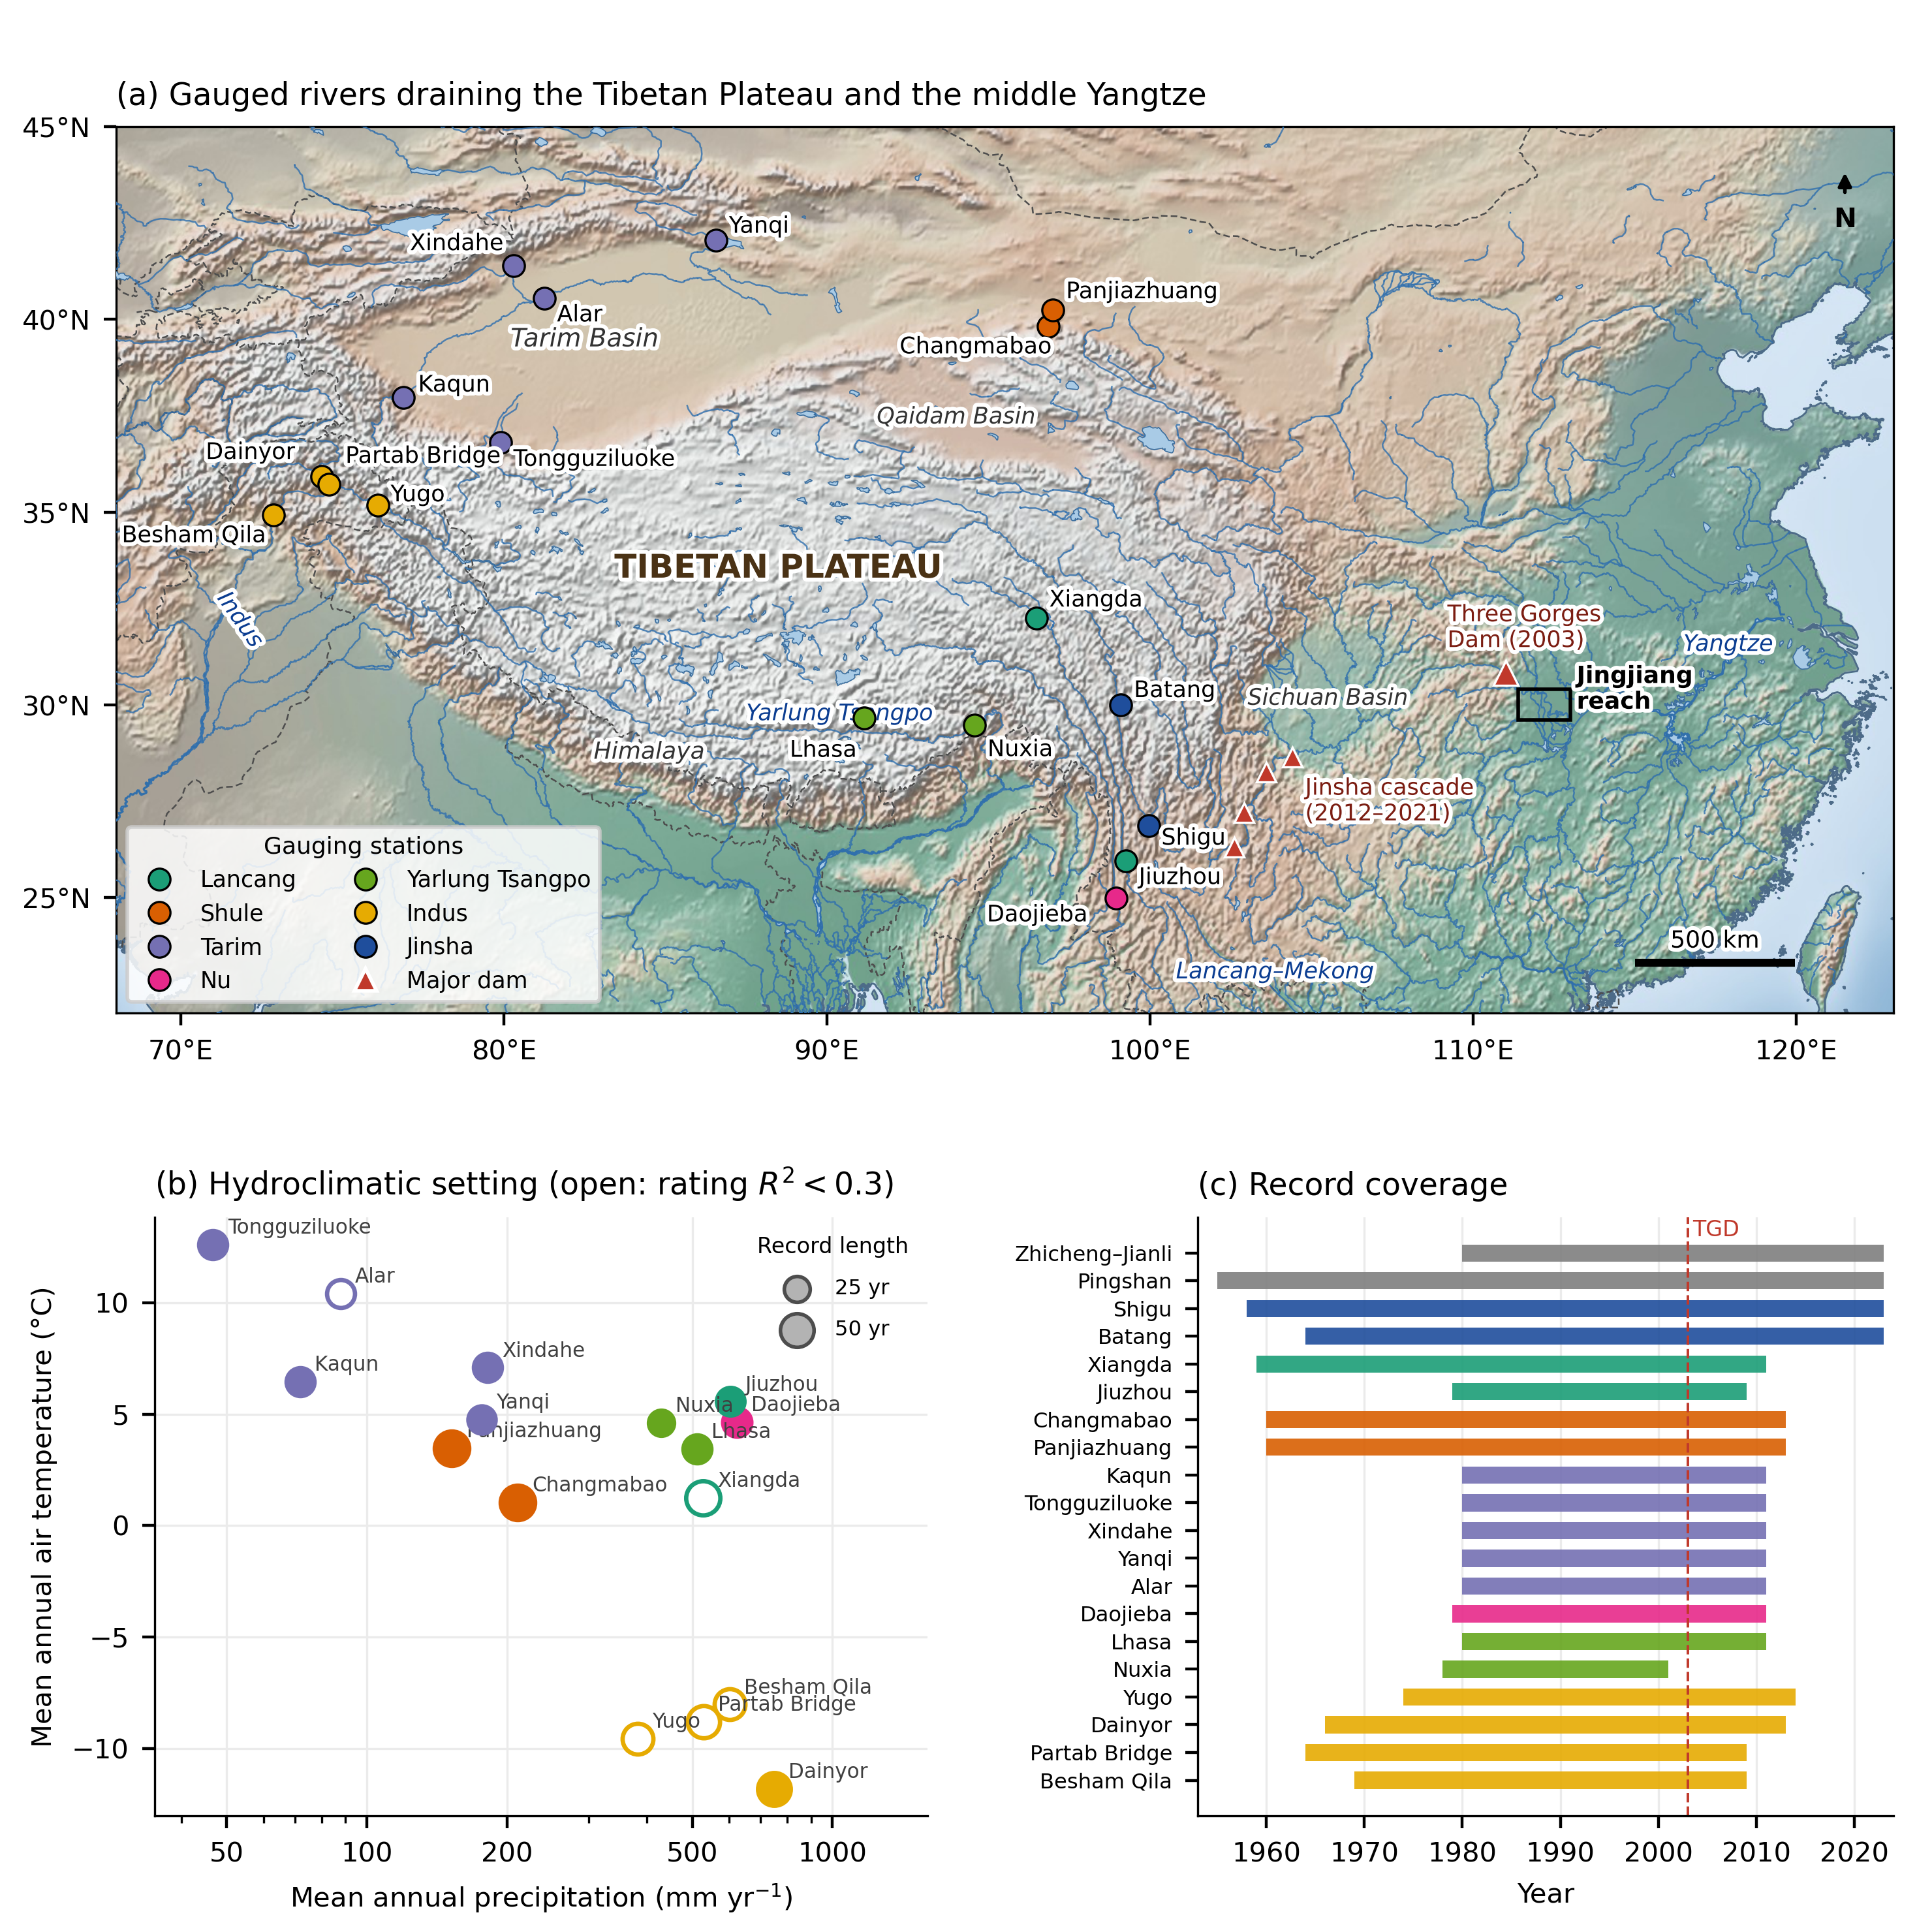

In [3]:
from IPython.display import Image, display
display(Image(os.path.join(FIG, 'Fig1_study_domain.png'), width=800))